In [18]:
import json
from pathlib import Path

import jax
import jax.numpy as jnp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import ICIW_Plots

from ipywidgets import interact, IntSlider

plt.style.use("ICIWstyle")

In [19]:
from HSA_L_001 import (
    TRUE_PARAMS,
    PARAM_NAMES,
    DESIGN_NAMES,
    LOG_PARAMS,
    DH_SCALE,
    RIDGE,
    X_LB,
    X_UB,
    to_phys,
)

In [20]:
exp_run_name = "misleading-botswana"  # grid start: "relaxed-action"
data_path = Path(f"data/{exp_run_name}/seed042")
sum_file = data_path / "experiment_summary.json"

In [21]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

steps = exp_summary["steps"]
n_init = steps[0]["n_experiments"]
proposals = np.array(steps[-1]["observed"]["x"])
r_obs = np.array(steps[-1]["observed"]["y"])
n_exp = np.array([s["n_experiments"] for s in steps])
print(
    f"{len(steps)} steps, {n_init} initial + {len(proposals) - n_init} designed experiments"
)

33 steps, 8 initial + 32 designed experiments


# Uncertainty from the FIM

For a least-squares fit with Gaussian noise the FIM is the curvature of the
log-likelihood at $\hat\theta$. Its inverse gives the asymptotic covariance of the
estimate (Cramér–Rao / Laplace approximation):

$$\hat\theta \;\dot\sim\; \mathcal{N}\!\left(\theta,\; \mathrm{FIM}^{-1}\right),
\qquad \sigma_j = \sqrt{\left[\mathrm{FIM}^{-1}\right]_{jj}}$$

so a 95 % interval is $\hat\theta_j \pm 1.96\,\sigma_j$. With a flat prior this is
exactly the 95 % HDI of the Laplace-approximated posterior, so it is the
frequentist counterpart of the HDIs in the HSA_K notebooks.

Some caveats:
* It is computed in the **fitted** space ($\log k_0$, $\log E_\mathrm{A}$, $\log A_i$,
  $\Delta H_i/10^4$). For the log parameters the interval is symmetric in log space,
  so it becomes asymmetric in physical units: equal-tailed, not strictly the HDI of
  the lognormal.
* It is **local**: linearised at $\hat\theta$. With few experiments the model is
  strongly nonlinear in $\theta$ and the interval is typically too narrow.
* While the FIM is rank deficient, the unidentifiable directions have infinite
  variance. `pinv` silently drops them; here we invert $\mathrm{FIM} + 10^{-6} I$
  (the same ridge as the design objective), so those parameters show up as huge
  intervals instead of fake certainty.

In [22]:
Z95 = norm.ppf(0.975)
true_phys = np.array(list(TRUE_PARAMS.values()))


def intervals(step, z=Z95):
    """Estimate and 95% Wald interval in physical units from the stored FIM."""
    F = np.array(step["fim"])
    theta = np.array(step["theta"])
    cov = np.linalg.inv(F + RIDGE * np.eye(len(theta)))
    sd = np.sqrt(np.diag(cov))
    lo = np.asarray(to_phys(jnp.array(theta - z * sd)))
    hi = np.asarray(to_phys(jnp.array(theta + z * sd)))
    est = np.asarray(to_phys(jnp.array(theta)))
    return est, lo, hi, sd, cov


ints = [intervals(s) for s in steps]
est = np.array([i[0] for i in ints])
lo = np.array([i[1] for i in ints])
hi = np.array([i[2] for i in ints])
sd = np.array([i[3] for i in ints])
rank = np.array([np.linalg.matrix_rank(np.array(s["fim"])) for s in steps])
logdet = np.array([s["logdet_fim"] for s in steps])

In [23]:
final = pd.DataFrame(
    {
        "estimate": est[-1],
        "2.5 %": lo[-1],
        "97.5 %": hi[-1],
        "true": true_phys,
        "sd (fitted space)": sd[-1],
        "covered": (lo[-1] <= true_phys) & (true_phys <= hi[-1]),
    },
    index=PARAM_NAMES,
)
final.style.format(
    {
        "estimate": "{:.4g}",
        "2.5 %": "{:.4g}",
        "97.5 %": "{:.4g}",
        "true": "{:.4g}",
        "sd (fitted space)": "{:.3f}",
    }
)

,estimate,2.5 %,97.5 %,true,sd (fitted space),covered
k0,0.0003415,0.0002984,0.0003908,0.000346,0.069,True
Ea_k,7.807e+04,7.413e+04,8.221e+04,7.75e+04,0.026,True
A_oh,0.4966,0.4498,0.5483,0.5,0.051,True
dH_oh,2.215e+04,1.792e+04,2.639e+04,2.24e+04,0.216,True
A_h2,0.4065,0.3382,0.4885,0.44,0.094,True
dH_h2,-6746,-1.159e+04,-1906,-6200,0.247,True
A_mix,0.903,0.7785,1.047,0.88,0.076,True
dH_mix,-1.013e+04,-1.411e+04,-6156,-1e+04,0.203,True


# Exploration pattern

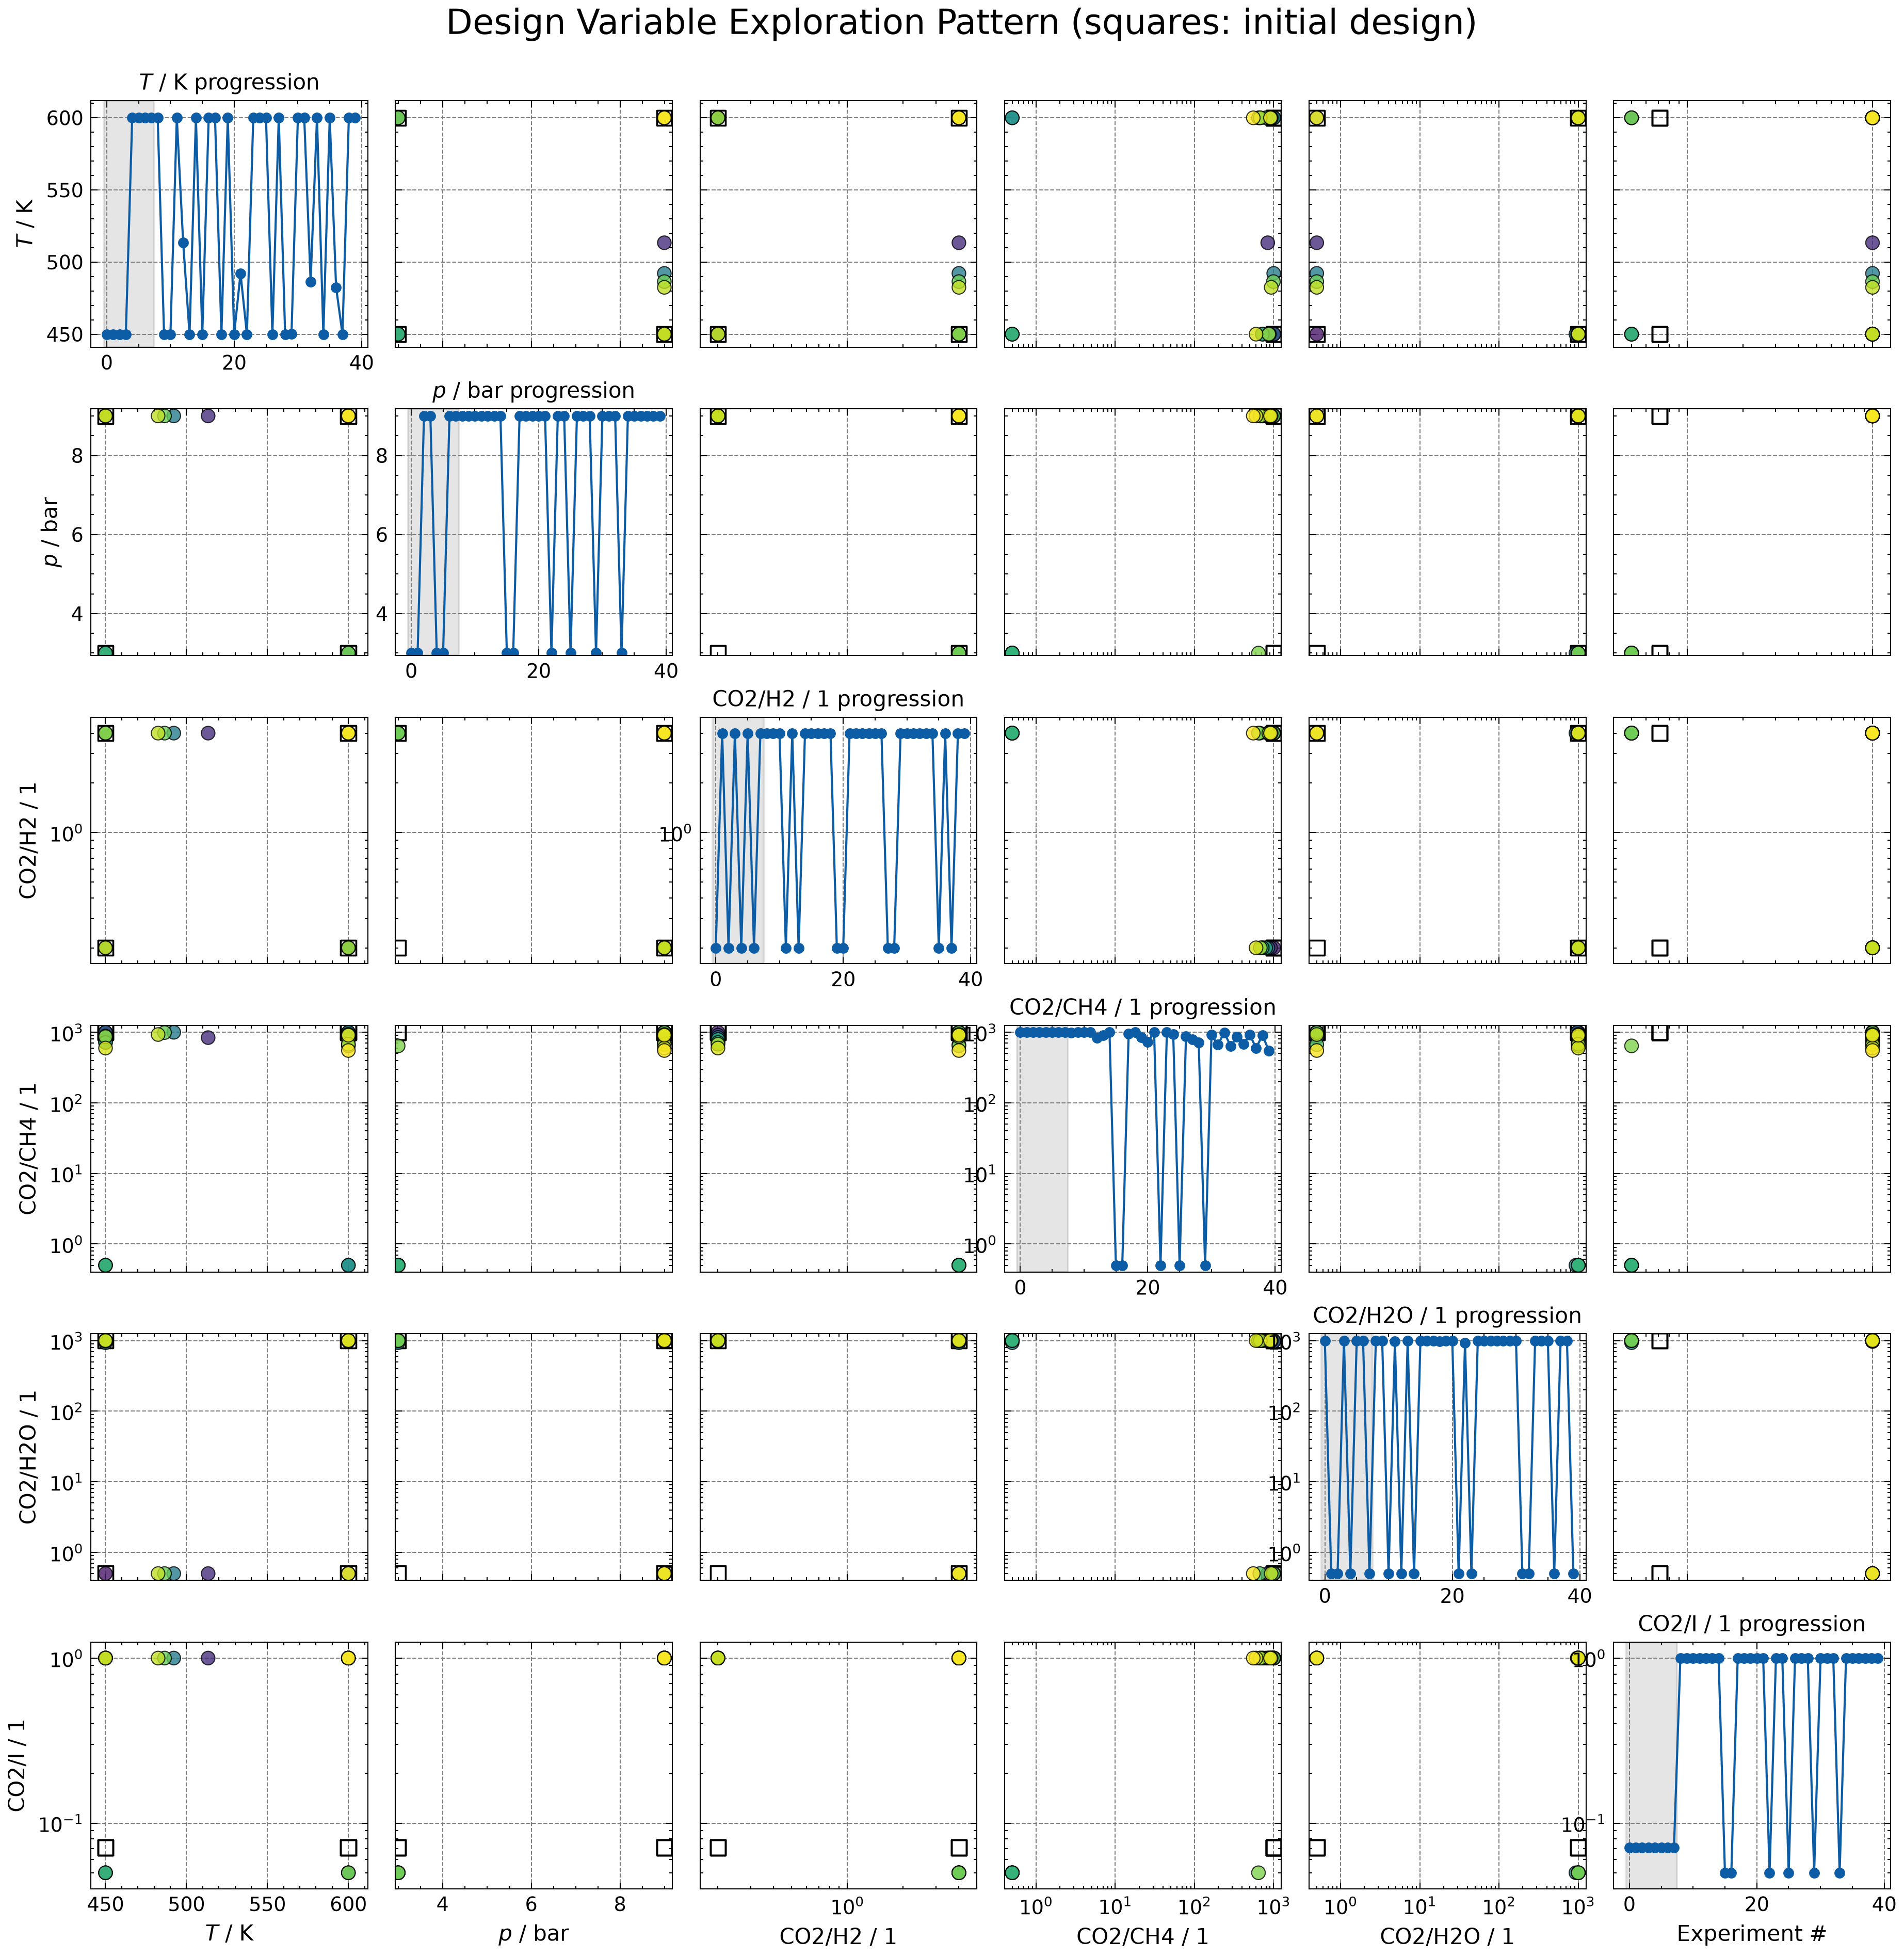

In [24]:
# 6x6 matrix plot: diagonal = progression of each design variable, off-diagonal = pairwise scatter
n_var = len(DESIGN_NAMES)
fig, axs = plt.subplots(
    n_var,
    n_var,
    figsize=(15, 15),
    gridspec_kw={"hspace": 0.25, "wspace": 0.1},
)

var_names = [
    r"$T$ / K",
    r"$p$ / bar",
    r"CO2/H2 / 1",
    r"CO2/CH4 / 1",
    r"CO2/H2O / 1",
    r"CO2/I / 1",
]
log_vars = [False, False, True, True, True, True]

n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)
designed = experiment_order >= n_init

for i in range(n_var):
    for j in range(n_var):
        ax = axs[i, j]

        if i == j:  # Diagonal: progression of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=1, markersize=4)
            ax.axvspan(-0.5, n_init - 0.5, color="grey", alpha=0.2)
            ax.set_ylim(
                X_LB[i] * (0.8 if log_vars[i] else 0.98),
                X_UB[i] * (1.25 if log_vars[i] else 1.02),
            )
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
        else:  # Off-diagonal: colored by experiment order, initial design as squares
            ax.scatter(
                proposals[~designed, j],
                proposals[~designed, i],
                marker="s",
                facecolor="none",
                edgecolors="black",
                s=50,
                linewidth=0.8,
            )
            ax.scatter(
                proposals[designed, j],
                proposals[designed, i],
                c=experiment_order[designed],
                cmap="viridis",
                s=40,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )
            ax.set_xlim(
                X_LB[j] * (0.8 if log_vars[j] else 0.98),
                X_UB[j] * (1.25 if log_vars[j] else 1.02),
            )
            ax.set_ylim(
                X_LB[i] * (0.8 if log_vars[i] else 0.98),
                X_UB[i] * (1.25 if log_vars[i] else 1.02),
            )
            if log_vars[j]:
                ax.set_xscale("log")
                ax.xaxis.set_minor_formatter(plt.NullFormatter())
        if log_vars[i]:
            ax.set_yscale("log")
            ax.yaxis.set_minor_formatter(plt.NullFormatter())

        # Set labels only on edges
        if i == n_var - 1:
            ax.set_xlabel("Experiment #" if i == j else var_names[j], fontsize=10)
        if j == 0:
            ax.set_ylabel(var_names[i], fontsize=10)
        if i < n_var - 1 and i != j:
            ax.set_xticklabels([])
        if j > 0 and i != j:
            ax.set_yticklabels([])

plt.suptitle(
    "Design Variable Exploration Pattern (squares: initial design)", fontsize=16, y=0.92
)
plt.show()

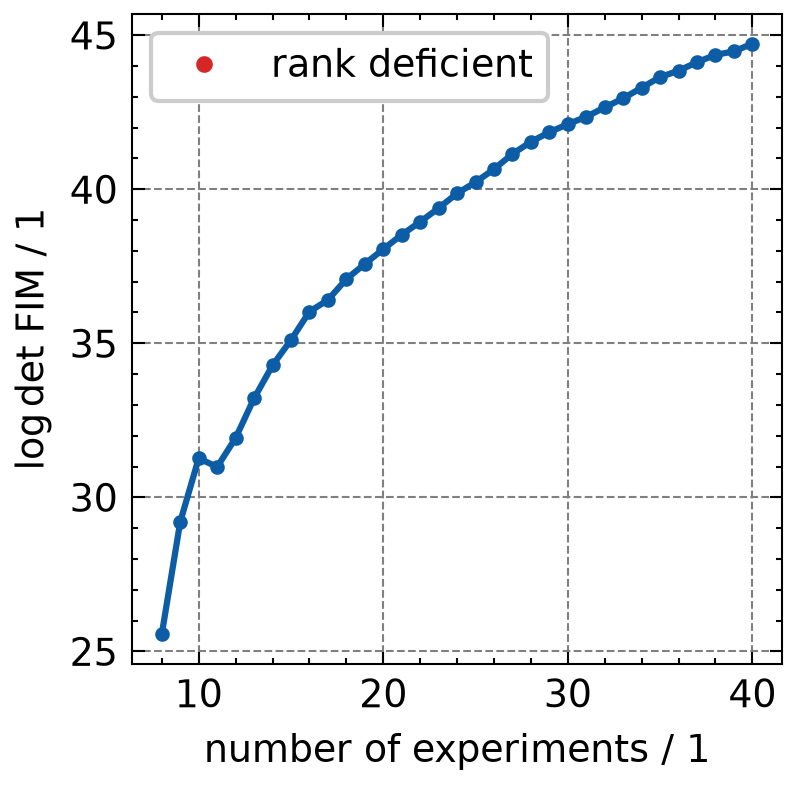

In [25]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\log\det\,\mathrm{FIM}$ / 1",
)
ax.plot(n_exp, logdet, marker="o", ms=2.5)
ax.plot(
    n_exp[rank < len(PARAM_NAMES)],
    logdet[rank < len(PARAM_NAMES)],
    "o",
    ms=3,
    color="tab:red",
    label="rank deficient",
)
ax.legend(frameon=True)
plt.show()

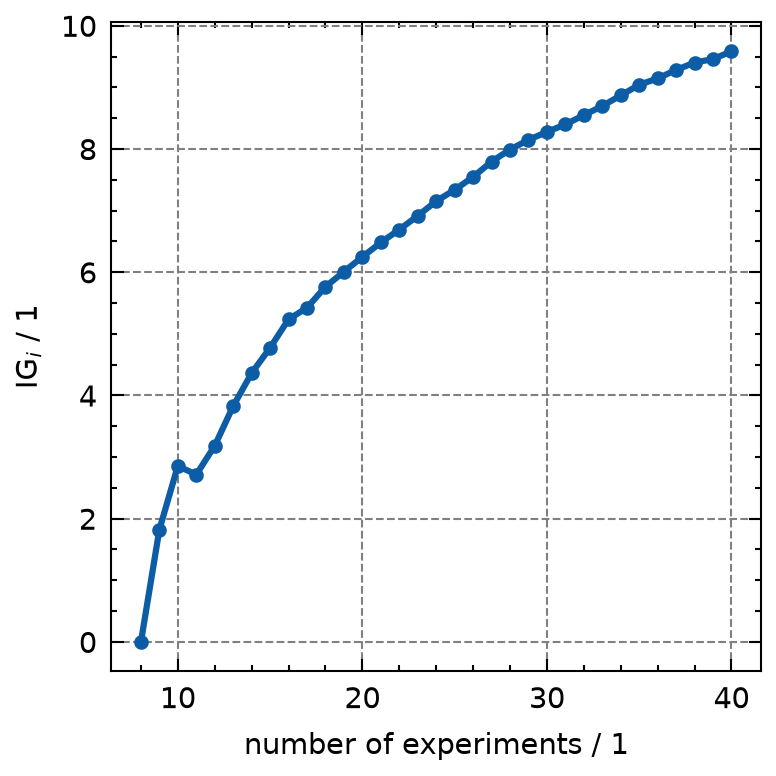

In [42]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
)
IG = (logdet - logdet[0]) / 2
ax.plot(n_exp, IG, marker="o", ms=2.5)
# ax.legend(frameon=True)
plt.savefig(f"figures/L/mbDOE_IG.png")
plt.savefig(f"figures/L/mbDOE_IG.pdf")
plt.show()

## Total information gain

Laplace approximation of the information gain relative to the **K-series prior**
(`HSA_Mo_B_011.bayesian_model`), so the first 8 experiments are counted too.
The independent priors are moment-matched in the fitted space: the log of an
exponential has variance $\pi^2/6$ and mean $\log m - \gamma$ regardless of its scale $m$;
$\Delta H_\mathrm{OH}/10^4 \sim \mathrm{Exp}(1)$; $\Delta H_\mathrm{H_2}/10^4,\ \Delta H_\mathrm{mix}/10^4 \sim \mathcal{N}(-1, 0.5^2)$.

* **expected** (the bDOE quantity): $\tfrac12\log\det(I + \Sigma_p\,\mathrm{FIM}_n)$, every FIM evaluated at the
  final $\hat\theta$ so the curve only reflects added data
* **realised**: Gaussian $\mathrm{KL}\big(\mathcal{N}(\hat\theta_n, \Sigma_n)\,\|\,\mathcal{N}(\mu_p, \Sigma_p)\big)$ with
  $\Sigma_n = (\Sigma_p^{-1} + \mathrm{FIM}_n)^{-1}$, comparable to the total IG in HSA_K_001. It
  depends on where $\hat\theta_n$ lands, so it need not increase monotonically.

Caveats: skewed / positive priors replaced by Gaussians (least reliable early on);
$\sigma_\mathrm{rel}$ is treated as known, while the K model learns `sigma_r` as a 9th parameter.

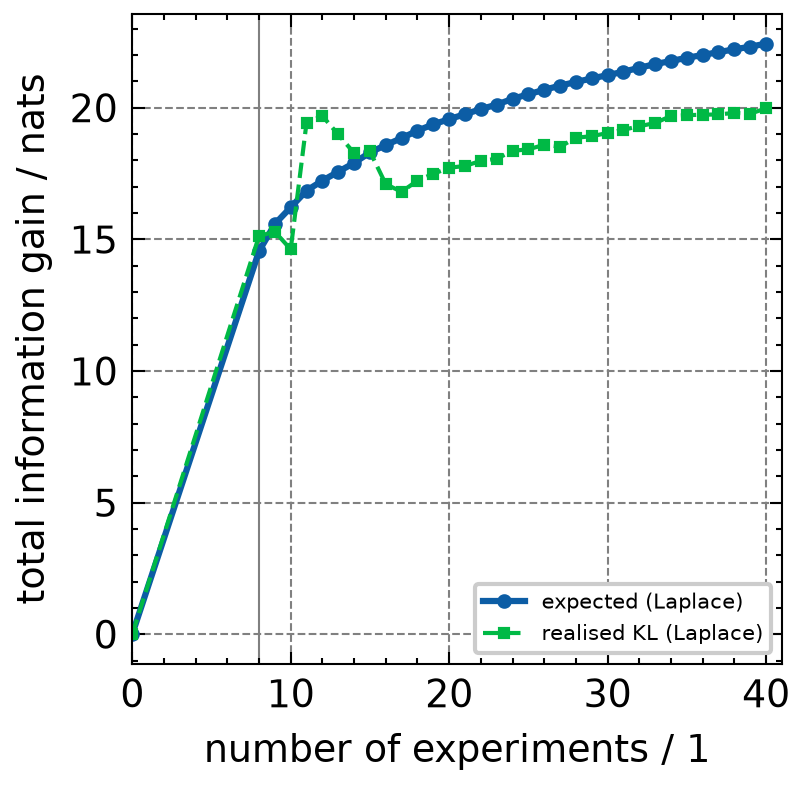

In [27]:
from HSA_L_001 import fim

# K-series prior (HSA_Mo_B_011.bayesian_model), moment-matched in the fitted space
g, v = np.euler_gamma, np.pi**2 / 6
Sigma_p = np.diag([v, v, v, 1.0, v, 0.25, v, 0.25])
mu_p = np.array([np.log(1e-3) - g, np.log(6e4) - g, -g, 1.0, -g, -1.0, -g, -1.0])
Sigma_p_inv = np.linalg.inv(Sigma_p)
theta_ref = jnp.array(steps[-1]["theta"])

IG_exp, IG_real = [], []
for s in steps:
    F_ref = np.asarray(fim(theta_ref, jnp.array(s["observed"]["x"])))
    IG_exp.append(0.5 * np.linalg.slogdet(np.eye(8) + Sigma_p @ F_ref)[1])

    S_n = np.linalg.inv(Sigma_p_inv + np.array(s["fim"]))
    d = np.array(s["theta"]) - mu_p
    IG_real.append(
        0.5
        * (
            np.trace(Sigma_p_inv @ S_n)
            + d @ Sigma_p_inv @ d
            - 8
            + np.linalg.slogdet(Sigma_p)[1]
            - np.linalg.slogdet(S_n)[1]
        )
    )

fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"total information gain / nats",
    xlim=(0, n_exp[-1] + 1),
)
ax.plot(
    np.r_[0, n_exp], np.r_[0, IG_exp], marker="o", ms=2.5, label="expected (Laplace)"
)
ax.plot(
    np.r_[0, n_exp],
    np.r_[0, IG_real],
    marker="s",
    ms=2,
    lw=1,
    ls="--",
    label="realised KL (Laplace)",
)
ax.axvline(n_init, color="grey", linewidth=0.5, zorder=0)
ax.legend(frameon=True, fontsize=5)
plt.show()

## The parameter estimates over the DOE

In [28]:
plt.rcParams.update(
    {
        "font.size": 7,
        "figure.dpi": 300,
    },
)

/home/hannes/Documents/PythonCode/BIBO/.venv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
/home/hannes/Documents/PythonCode/BIBO/.venv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


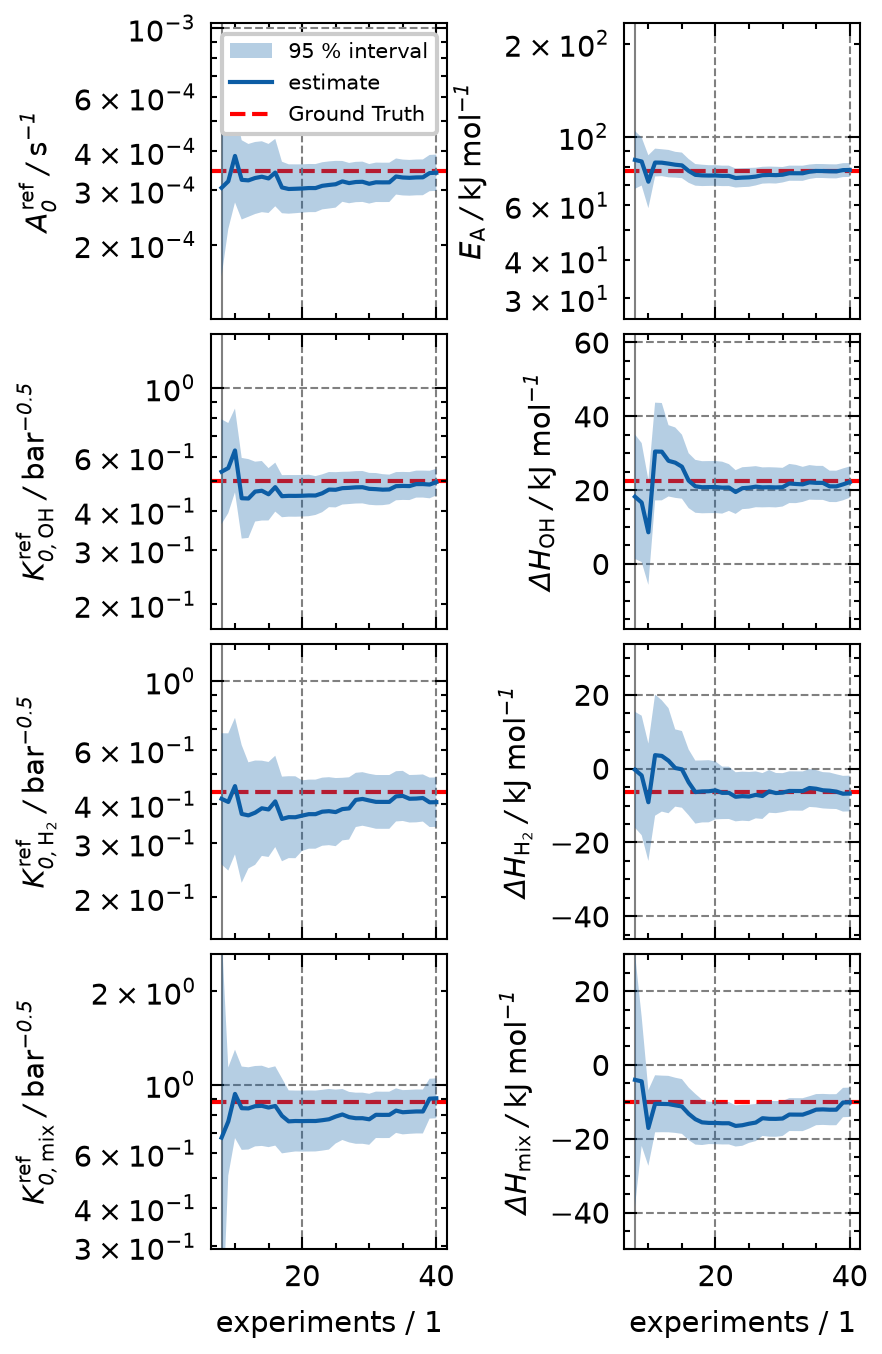

In [29]:
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}
kJ_params = ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]

fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

for idx, param in enumerate(PARAM_NAMES):
    ax = axes[idx]
    scale = 1e-3 if param in kJ_params else 1.0
    true_val = true_phys[idx] * scale

    ax.fill_between(
        n_exp,
        lo[:, idx] * scale,
        hi[:, idx] * scale,
        alpha=0.3,
        lw=0,
        label="95 % interval",
    )
    ax.plot(n_exp, est[:, idx] * scale, lw=1, label="estimate")
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )
    ax.axvline(n_init, color="grey", linewidth=0.5, zorder=0)

    # the early, rank-deficient intervals are effectively unbounded: clip the view around the truth
    if LOG_PARAMS[idx]:
        ax.set_yscale("log")
        ax.set_ylim(true_val / 3, true_val * 3)
    else:
        ax.set_ylim(true_val - 40, true_val + 40)
    ax.set_ylabel(labeldict[param])
    if idx >= 6:
        ax.set_xlabel("experiments / 1")
    else:
        ax.set_xticklabels([])

axes[0].legend(fontsize=5, loc="upper right")
# plt.savefig("figures/KinFit_L_parameter_progression.png")
# plt.savefig("figures/KinFit_L_parameter_progression.svg")
# plt.savefig("figures/KinFit_L_parameter_progression.pdf")
plt.show()

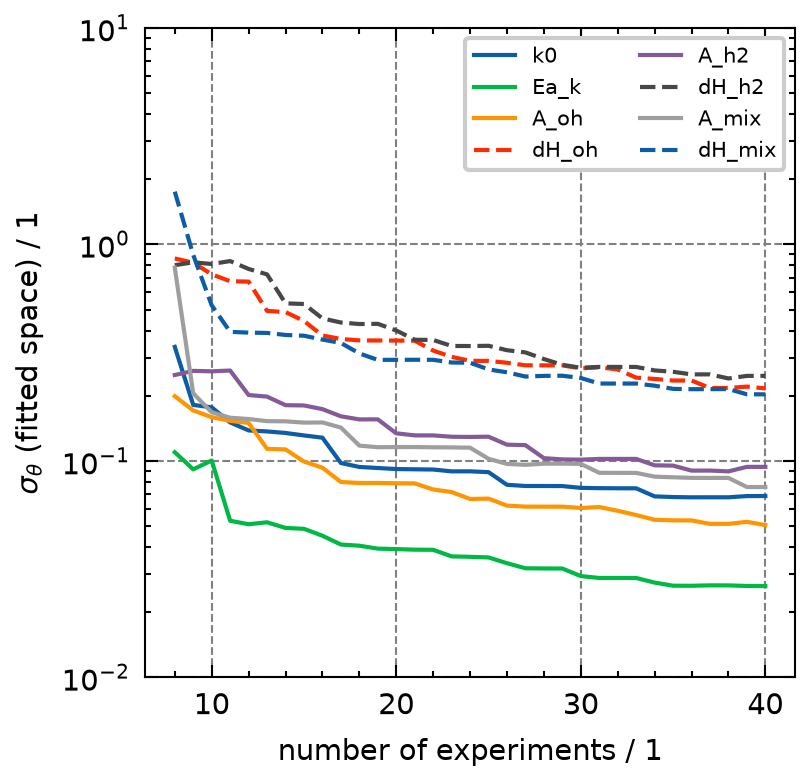

In [30]:
# relative width of the 95 % interval in the fitted space, i.e. ~ relative uncertainty for log-params
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\sigma_\theta$ (fitted space) / 1",
    yscale="log",
    ylim=(1e-2, 1e1),
)
for idx, param in enumerate(PARAM_NAMES):
    ax.plot(n_exp, sd[:, idx], lw=1, ls="-" if LOG_PARAMS[idx] else "--", label=param)
ax.legend(fontsize=5, ncols=2)
plt.show()

## Final estimates compared to GT

/home/hannes/Documents/PythonCode/BIBO/.venv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
/home/hannes/Documents/PythonCode/BIBO/.venv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


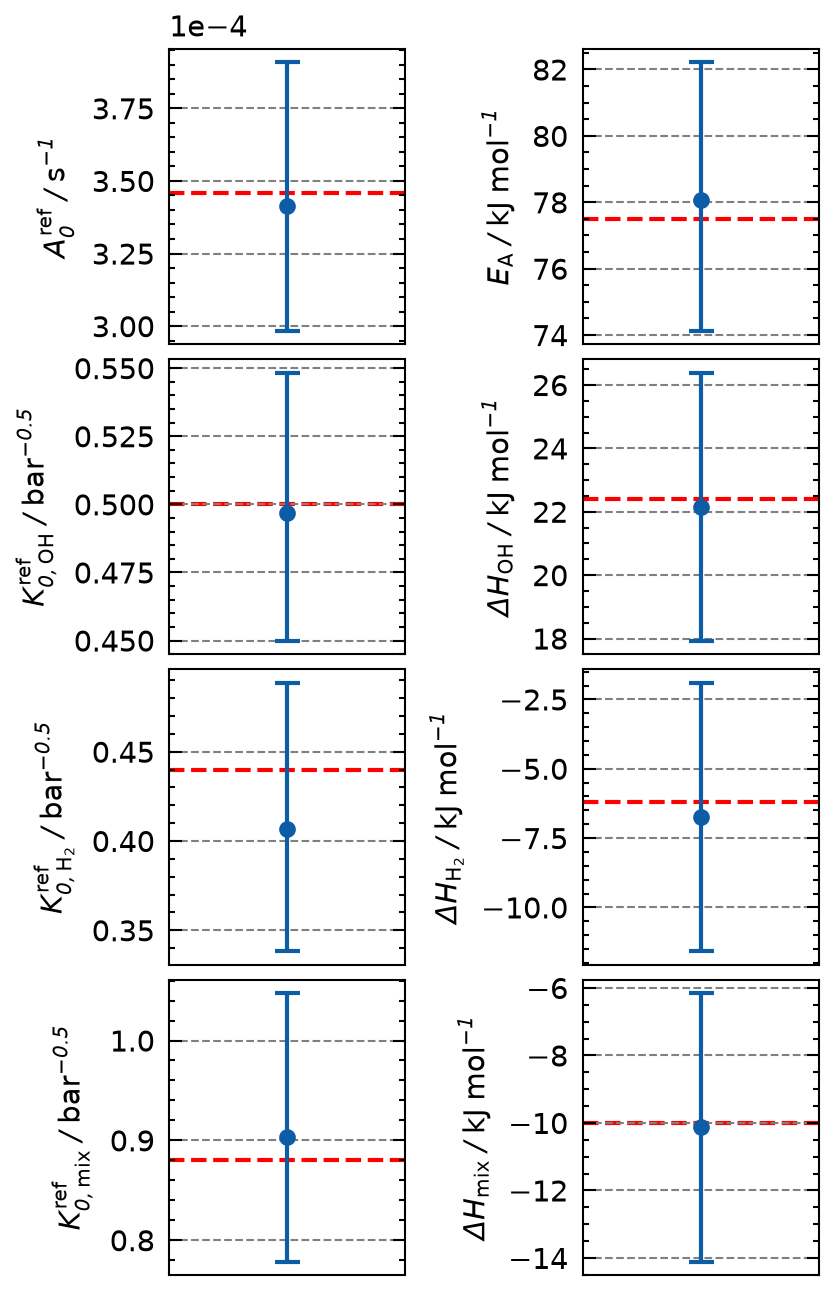

In [31]:
fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

for idx, param in enumerate(PARAM_NAMES):
    ax = axes[idx]
    scale = 1e-3 if param in kJ_params else 1.0
    e, l, h = est[-1, idx] * scale, lo[-1, idx] * scale, hi[-1, idx] * scale

    ax.errorbar([0], [e], yerr=[[e - l], [h - e]], fmt="o", ms=3, capsize=3, lw=1)
    ax.axhline(
        y=true_phys[idx] * scale,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(labeldict[param])
    ax.set_xlim(-1, 1)
    ax.set_xticks([])
    ax.grid(False, axis="x")

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.show()

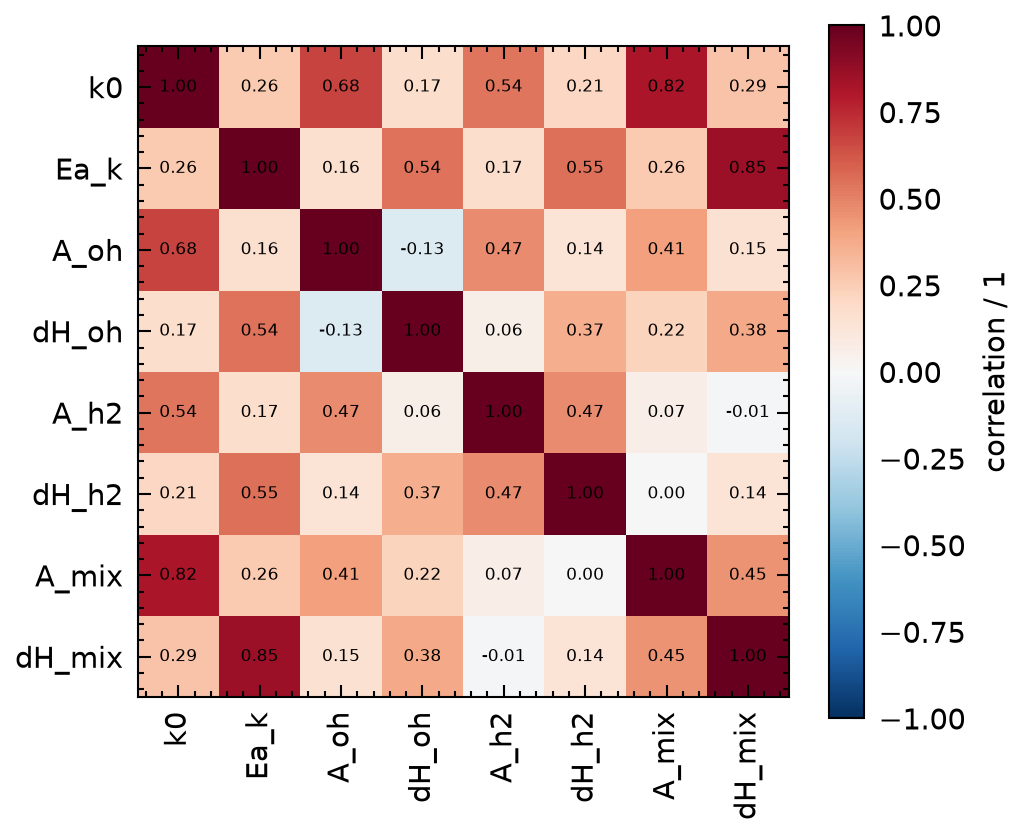

In [32]:
# parameter correlations from FIM^-1 at the final step
cov = ints[-1][4]
corr = cov / np.outer(np.sqrt(np.diag(cov)), np.sqrt(np.diag(cov)))

fig, ax = plt.subplots(figsize=(3.5, 3.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(PARAM_NAMES)), PARAM_NAMES, rotation=90)
ax.set_yticks(range(len(PARAM_NAMES)), PARAM_NAMES)
ax.grid(False)
for a in range(len(PARAM_NAMES)):
    for b in range(len(PARAM_NAMES)):
        ax.text(b, a, f"{corr[a, b]:.2f}", ha="center", va="center", fontsize=4)
fig.colorbar(im, ax=ax, label="correlation / 1")
plt.show()

In [33]:
@interact(
    i=IntSlider(
        min=0, max=len(steps) - 1, step=1, value=len(steps) - 1, description="Step:"
    )
)
def show_step(i):
    df = pd.DataFrame(
        {"estimate": est[i], "2.5 %": lo[i], "97.5 %": hi[i], "true": true_phys},
        index=PARAM_NAMES,
    )
    print(f"step {i}: n = {n_exp[i]}, rank(FIM) = {rank[i]}, logdet = {logdet[i]:.2f}")
    if steps[i]["next_proposal"] is not None:
        print(
            "next:", {k: round(v, 3) for k, v in steps[i]["next_proposal"]["x"].items()}
        )
    display(df.style.format("{:.4g}"))

interactive(children=(IntSlider(value=32, description='Step:', max=32), Output()), _dom_classes=('widget-inter…

# Comparison with the paramEKLD bDOE (HSA_K_001)

Final posteriors of the paramEKLD bDOE run (`selective-knight`, 5 seeds pooled, 32 experiments)
as violins ("bDOE"), next to the mbDOE estimates with their 95 % FIM intervals as error bars, both at the
same budget of 32 experiments and at the end of the mbDOE run (40 experiments).

The traces are read with plain `xarray`: `import arviz` currently fails in this venv
(`arviz_plots` vs. matplotlib), and nothing beyond the posterior group is needed here.

In [34]:
import xarray

bdoe_run = Path("data/selective-knight")
bdoe_seeds = sorted(bdoe_run.glob("seed*"))
THIN = 4  # 32000 -> 8000 draws per seed, plenty for a KDE


def final_posterior(seed_dir):
    trace = sorted(seed_dir.glob("trace_*.nc"))[-1]
    post = xarray.open_datatree(trace)["posterior"].dataset
    n_obs = post.sizes["r_pred_dim_0"]
    return {
        p: post[p].values.ravel()[::THIN].astype(np.float64) for p in PARAM_NAMES
    }, n_obs


bdoe = [final_posterior(s) for s in bdoe_seeds]
bdoe_n = {n for _, n in bdoe}
bdoe_samples = {p: np.concatenate([b[p] for b, _ in bdoe]) for p in PARAM_NAMES}
print(f"{len(bdoe_seeds)} seeds, experiments per seed: {bdoe_n}")

5 seeds, experiments per seed: {32}


/home/hannes/Documents/PythonCode/BIBO/.venv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
/home/hannes/Documents/PythonCode/BIBO/.venv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


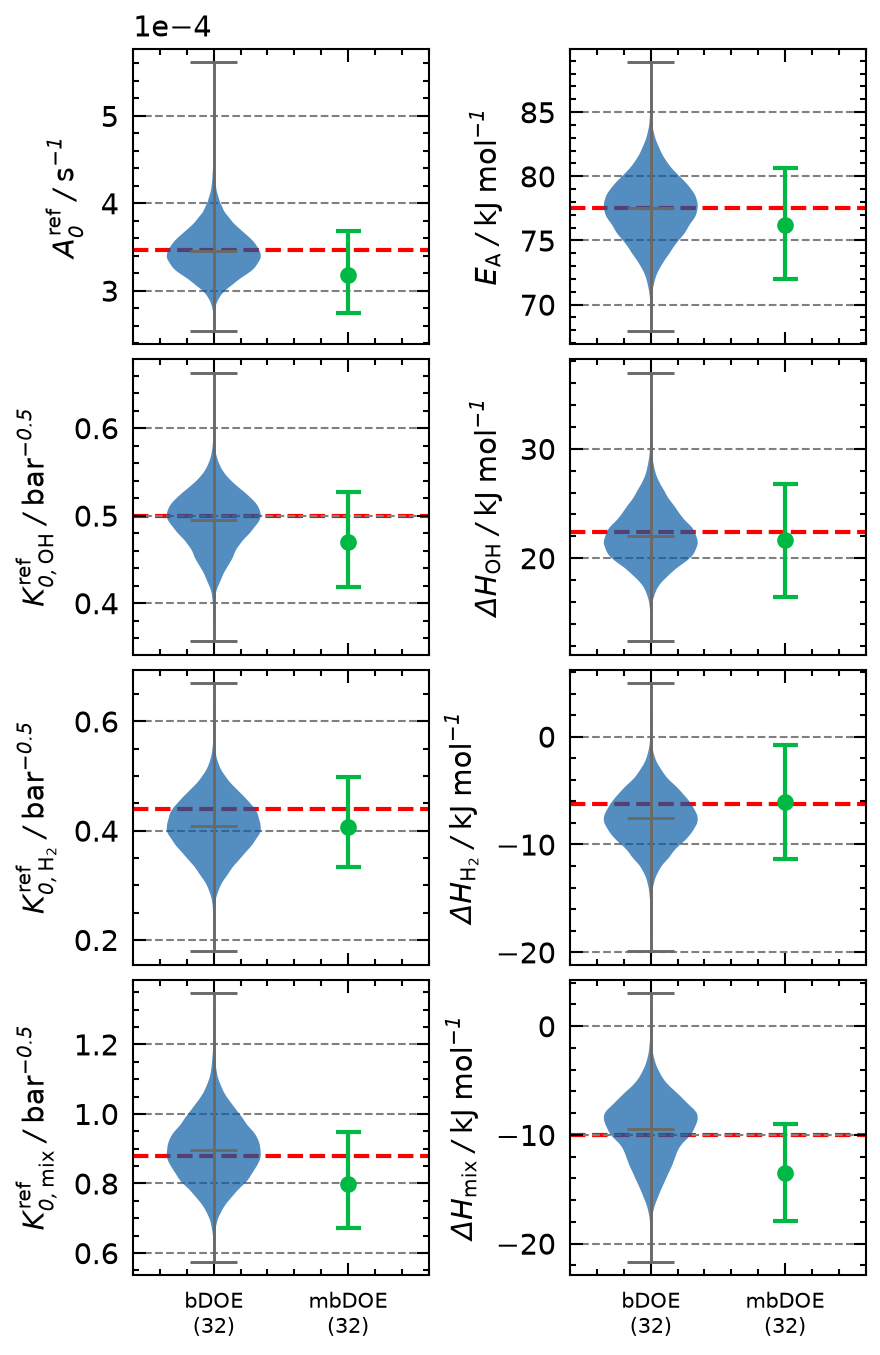

In [40]:
n_budget = max(bdoe_n)
k_budget = int(np.flatnonzero(n_exp == n_budget)[0])
mb_steps = [
    (k_budget, f"mbDOE\n({n_budget})"),
    # (len(steps) - 1, f"mbDOE\n({n_exp[-1]})"),
]

fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.5 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.2 * ICIW_Plots.cm2inch,
    left_h=1.01 * ICIW_Plots.cm2inch,
    bottom_v=1.5 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
xlabels = [f"bDOE\n({n_budget})"] + [label for _, label in mb_steps]

for idx, param in enumerate(PARAM_NAMES):
    ax = axes[idx]
    scale = 1e-3 if param in kJ_params else 1.0

    # bDOE: posterior violin
    parts = ax.violinplot(
        bdoe_samples[param] * scale, positions=[0], showmeans=True, widths=0.7
    )
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:
            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)
    for pc in parts["bodies"]:
        pc.set_facecolor(colors[0])
        pc.set_alpha(0.7)

    # mbDOE: estimate with 95 % FIM interval
    for pos, (k, _) in enumerate(mb_steps, start=1):
        e, l, h = est[k, idx] * scale, lo[k, idx] * scale, hi[k, idx] * scale
        ax.errorbar(
            [pos],
            [e],
            yerr=[[e - l], [h - e]],
            fmt="o",
            ms=3,
            capsize=3,
            lw=1,
            color=colors[pos],
        )

    ax.axhline(
        y=true_phys[idx] * scale, color="red", linestyle="--", linewidth=1.0, zorder=0
    )
    ax.set_ylabel(labeldict[param])
    ax.set_xlim(-0.6, len(mb_steps) + 0.6)
    ax.grid(False, axis="x")
    if idx >= 6:
        ax.set_xticks(range(len(xlabels)), xlabels, fontsize=5)
    else:
        ax.set_xticks(range(len(xlabels)), [])

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.savefig("figures/L/param_comp_mbDOE_bDOE.png")
plt.savefig("figures/L/param_comp_mbDOE_bDOE.pdf")
# plt.savefig("figures/KinFit_L_vs_K_parameter_comparison.png")
# plt.savefig("figures/KinFit_L_vs_K_parameter_comparison.svg")
# plt.savefig("figures/KinFit_L_vs_K_parameter_comparison.pdf")
plt.show()

In [36]:
# widths of the 95 % intervals: central posterior interval (bDOE) vs. FIM interval (mbDOE)
rows = {}
for idx, param in enumerate(PARAM_NAMES):
    q_lo, q_hi = np.quantile(bdoe_samples[param], [0.025, 0.975])
    rows[param] = {
        "true": true_phys[idx],
        f"paramEKLD ({n_budget}) 2.5 %": q_lo,
        f"paramEKLD ({n_budget}) 97.5 %": q_hi,
    }
    for k, label in mb_steps:
        label = label.replace("\n", " ")
        rows[param][f"{label} 2.5 %"] = lo[k, idx]
        rows[param][f"{label} 97.5 %"] = hi[k, idx]
pd.DataFrame(rows).T.style.format("{:.4g}")

,true,paramEKLD (32) 2.5 %,paramEKLD (32) 97.5 %,mbDOE (32) 2.5 %,mbDOE (32) 97.5 %,mbDOE (40) 2.5 %,mbDOE (40) 97.5 %
k0,0.000346,0.0002971,0.0004072,0.0002745,0.0003679,0.0002984,0.0003908
Ea_k,7.75e+04,7.26e+04,8.244e+04,7.202e+04,8.062e+04,7.413e+04,8.221e+04
A_oh,0.5,0.4273,0.5556,0.4184,0.527,0.4498,0.5483
dH_oh,2.24e+04,1.745e+04,2.755e+04,1.647e+04,2.683e+04,1.792e+04,2.639e+04
A_h2,0.44,0.3032,0.5115,0.3333,0.4974,0.3382,0.4885
dH_h2,-6200,-1.266e+04,-2623,-1.139e+04,-743.9,-1.159e+04,-1906
A_mix,0.88,0.7247,1.086,0.6717,0.9485,0.7785,1.047
dH_mix,-1e+04,-1.569e+04,-3931,-1.794e+04,-9019,-1.411e+04,-6156
